In [6]:
import os, glob
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!date
!python --version
!nvidia-smi
import torch
print("PyTorch version:", torch.__version__, "| GPU ready:", torch.cuda.is_available())

Fri Oct 23 10:31:51 PM UTC 2026
Python 3.13.16
Fri Oct 23 22:31:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+

In [7]:
# Automatically finding '8410/Ass1/Assignment 1' folder in Google Drive
matches = glob.glob('/content/drive/MyDrive/3rd_sem/8410/Ass1/Assignment 1', recursive=True)
if not matches:
    matches = glob.glob('/content/drive/MyDrive/3rd_sem/8410/Ass1/Assignment 1', recursive=True)
BASE_DIR = matches[0]
EVAL_DIR = os.path.join(BASE_DIR, '60801131_Evaluation')
os.makedirs(EVAL_DIR, exist_ok=True)
os.chdir(EVAL_DIR)
print("Working folder set to:", os.getcwd())

Working folder set to: /content/drive/MyDrive/3rd_sem/8410/Ass1/Assignment 1/60801131_Evaluation


# Pair 1 (Week 2): Prompt-to-Prompt vs StyleAligned on shared U-Net

data loaded: torch.Size([2048, 1, 28, 28]) torch.Size([512, 1, 28, 28]) | first 4 test labels: ['Ankle boot', 'Pullover', 'Trouser', 'Trouser']
base warmup loss: 0.0397
[Pair 1 | System 1] Prompt-to-Prompt (prototype)         | TestMSE: 0.01218 | PertMSE: 0.02804 | Drift: 0.01894 | Lat(batch_64): 5.238ms
[Pair 1 | System 2] StyleAligned (prototype)             | TestMSE: 0.01190 | PertMSE: 0.02745 | Drift: 0.01887 | Lat(batch_64): 4.093ms


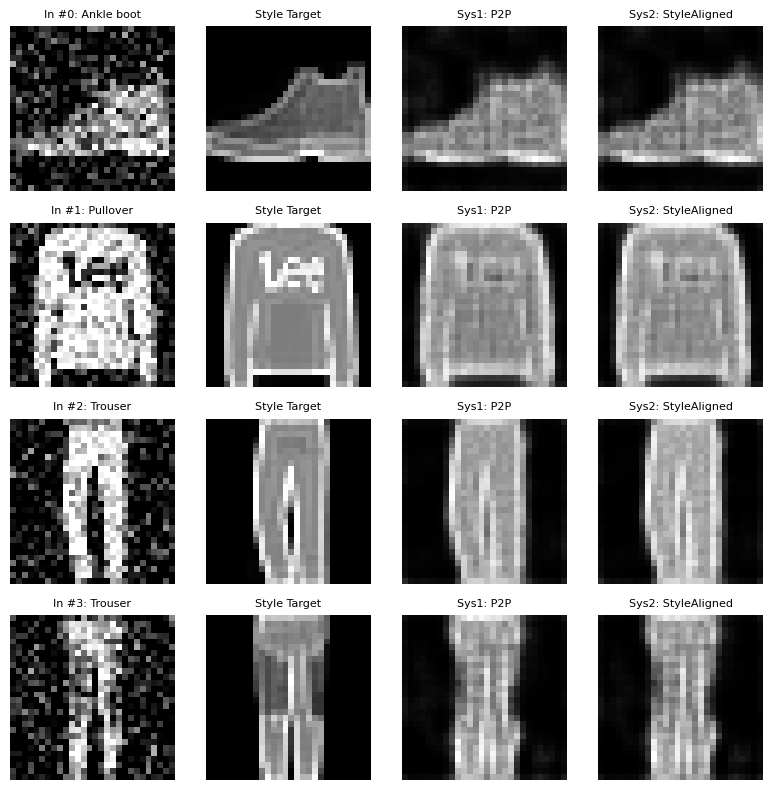

In [ ]:

import sys, os, time, math, copy, importlib
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd

if "src" not in sys.path:
    sys.path.insert(0, os.path.abspath("src"))

import profiler, w2_editing
importlib.reload(profiler)
importlib.reload(w2_editing)

from profiler import DEVICE, CLASS_NAMES, load_fashion_data, compute_error_stats, record_run
from w2_editing import make_style_edit_targets, SharedAttentionEditUNet

def now():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

x_tr, y_tr, x_te, y_te = load_fashion_data()
print("data loaded:", x_tr.shape, x_te.shape, "| first 4 test labels:", [CLASS_NAMES[int(c)] for c in y_te[:4]])

y_tr_style = make_style_edit_targets(x_tr)
y_te_style = make_style_edit_targets(x_te)

# pretrain one shared U-Net on both source (0..9) and style-edited (10..19) prompts
torch.manual_seed(42)
base_unet = SharedAttentionEditUNet().to(DEVICE)
opt_base = torch.optim.AdamW(base_unet.parameters(), lr=2e-3)

for step in range(50):
    idx = torch.randint(0, x_tr.size(0), (64,), device=DEVICE)
    xb = torch.clamp(x_tr[idx] + 0.25 * torch.randn_like(x_tr[idx]), 0.0, 1.0)
    out_src, _ = base_unet.forward_base(xb, y_tr[idx])
    out_edt, _ = base_unet.forward_base(xb, y_tr[idx] + 10)
    loss_b = F.mse_loss(out_src, x_tr[idx]) + F.mse_loss(out_edt, y_tr_style[idx])
    opt_base.zero_grad(); loss_b.backward(); opt_base.step()

print("base warmup loss:", round(loss_b.item(), 4))

# clone base weights so both attention methods start from the exact same checkpoint
p2p_net = copy.deepcopy(base_unet)
sa_net = copy.deepcopy(base_unet)

opt_p2p = torch.optim.AdamW(p2p_net.parameters(), lr=1e-3)
opt_sa = torch.optim.AdamW(sa_net.parameters(), lr=1e-3)

# style reference sample from training split
ref_img = y_tr_style[0:1]
ref_cls = y_tr[0:1]

# System 1: Prompt-to-Prompt (inject source self-attention map into edited pass)
t0 = now()
for _ in range(60):
    idx = torch.randint(0, x_tr.size(0), (64,), device=DEVICE)
    xb = torch.clamp(x_tr[idx] + 0.25 * torch.randn_like(x_tr[idx]), 0.0, 1.0)
    l1 = F.mse_loss(p2p_net.forward_prompt_to_prompt(xb, y_tr[idx], inject_weight=0.85), y_tr_style[idx])
    opt_p2p.zero_grad(); l1.backward(); opt_p2p.step()
t_p2p = now() - t0

# System 2: StyleAligned (share self-attention K, V with reference style image)
t0 = now()
for _ in range(60):
    idx = torch.randint(0, x_tr.size(0), (64,), device=DEVICE)
    xb = torch.clamp(x_tr[idx] + 0.25 * torch.randn_like(x_tr[idx]), 0.0, 1.0)
    l2 = F.mse_loss(sa_net.forward_style_aligned(xb, y_tr[idx], ref_img, ref_cls), y_tr_style[idx])
    opt_sa.zero_grad(); l2.backward(); opt_sa.step()
t_sa = now() - t0

p2p_net.eval(); sa_net.eval()
torch.manual_seed(99)
x_tr_eval = torch.clamp(x_tr[:512] + 0.25 * torch.randn_like(x_tr[:512]), 0.0, 1.0)
x_te_in = torch.clamp(x_te + 0.25 * torch.randn_like(x_te), 0.0, 1.0)
x_te_pert = torch.clamp(x_te + 0.50 * torch.randn_like(x_te), 0.0, 1.0)

if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
with torch.no_grad():
    t0 = now()
    for _ in range(20): _ = p2p_net.forward_prompt_to_prompt(x_te_in[:64], y_te[:64])
    lat_p2p = (now() - t0) * 1000.0 / 20.0
    tr_mse_p2p = F.mse_loss(p2p_net.forward_prompt_to_prompt(x_tr_eval, y_tr[:512]), y_tr_style[:512]).item()
    out_te_p2p = p2p_net.forward_prompt_to_prompt(x_te_in, y_te)
    out_pert_p2p = p2p_net.forward_prompt_to_prompt(x_te_pert, y_te)
vram_p2p = (torch.cuda.max_memory_allocated() / (1024**2)) if torch.cuda.is_available() else 0.0

if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
with torch.no_grad():
    t0 = now()
    for _ in range(20): _ = sa_net.forward_style_aligned(x_te_in[:64], y_te[:64], ref_img, ref_cls)
    lat_sa = (now() - t0) * 1000.0 / 20.0
    tr_mse_sa = F.mse_loss(sa_net.forward_style_aligned(x_tr_eval, y_tr[:512], ref_img, ref_cls), y_tr_style[:512]).item()
    out_te_sa = sa_net.forward_style_aligned(x_te_in, y_te, ref_img, ref_cls)
    out_pert_sa = sa_net.forward_style_aligned(x_te_pert, y_te, ref_img, ref_cls)
vram_sa = (torch.cuda.max_memory_allocated() / (1024**2)) if torch.cuda.is_available() else 0.0

st_p2p = compute_error_stats(out_te_p2p, y_te_style, out_pert_p2p, y_te_style, y_te, tr_mse_p2p)
st_sa = compute_error_stats(out_te_sa, y_te_style, out_pert_sa, y_te_style, y_te, tr_mse_sa)

cos_p2p = F.cosine_similarity(out_te_p2p.flatten(1), x_te.flatten(1), dim=-1).mean().item()
cos_sa = F.cosine_similarity(out_te_sa.flatten(1), x_te.flatten(1), dim=-1).mean().item()

record_run("Pair 1", "W2", "System 1", "Prompt-to-Prompt (prototype)", p2p_net, "batch_64", t_p2p, lat_p2p, vram_p2p, tr_mse_p2p, *st_p2p, aux_metric_name="Source_Cosine_Sim", aux_metric_val=cos_p2p)
record_run("Pair 1", "W2", "System 2", "StyleAligned (prototype)", sa_net, "batch_64", t_sa, lat_sa, vram_sa, tr_mse_sa, *st_sa, aux_metric_name="Source_Cosine_Sim", aux_metric_val=cos_sa)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i in range(4):
    lbl = CLASS_NAMES[int(y_te[i])]
    axes[i, 0].imshow(x_te_in[i, 0].cpu(), cmap="gray"); axes[i, 0].set_title(f"In #{i}: {lbl}", fontsize=8)
    axes[i, 1].imshow(y_te_style[i, 0].cpu(), cmap="gray"); axes[i, 1].set_title("Style Target", fontsize=8)
    axes[i, 2].imshow(out_te_p2p[i, 0].cpu(), cmap="gray"); axes[i, 2].set_title("Sys1: P2P", fontsize=8)
    axes[i, 3].imshow(out_te_sa[i, 0].cpu(), cmap="gray"); axes[i, 3].set_title("Sys2: StyleAligned", fontsize=8)
    for j in range(4): axes[i, j].axis("off")
plt.tight_layout()
plt.savefig("results/figures/pair1_w2_outputs.png", dpi=150)
plt.show()

# Pair 2 (Week 3): Custom Diffusion (token + W_K, W_V only) vs DreamBooth (full U-Net + CFG)

[Pair 2 | System 1] Custom Diffusion (prototype)         | TestMSE: 0.01771 | PertMSE: 0.03337 | Drift: 0.02694 | Lat(batch_64): 1.741ms
[Pair 2 | System 2] DreamBooth (prototype)               | TestMSE: 0.01533 | PertMSE: 0.03257 | Drift: 0.02833 | Lat(batch_64): 3.650ms


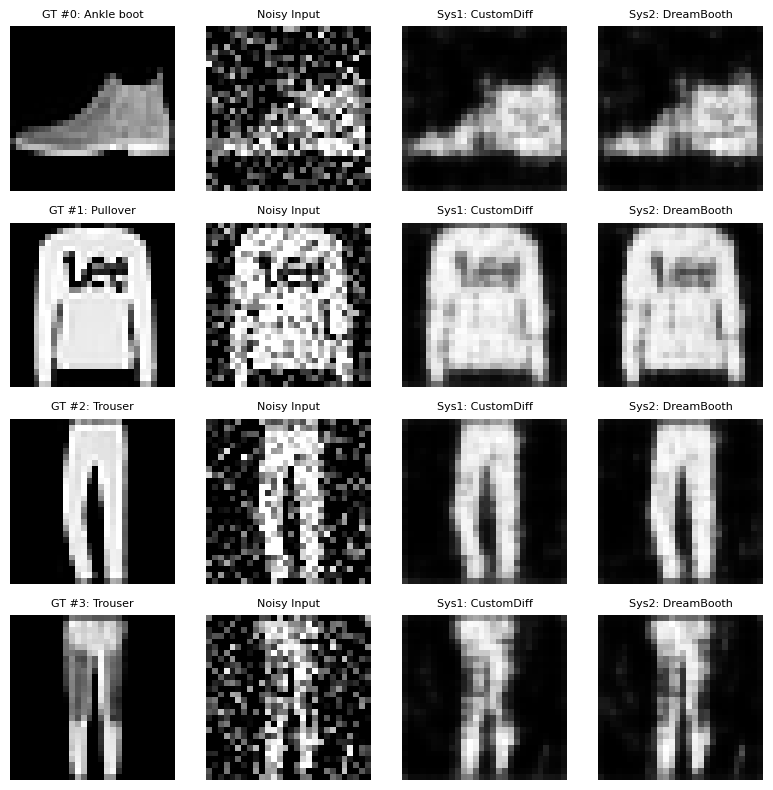

In [ ]:
import sys, os, time, math, importlib
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd

if "src" not in sys.path:
    sys.path.insert(0, os.path.abspath("src"))

import profiler, w3_personalization
importlib.reload(profiler)
importlib.reload(w3_personalization)

from profiler import DEVICE, CLASS_NAMES, load_fashion_data, compute_error_stats, record_run
from w3_personalization import CrossAttentionUNet2D

def now():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

x_tr, y_tr, x_te, y_te = load_fashion_data()

torch.manual_seed(42)
cust_model = CrossAttentionUNet2D().to(DEVICE)
db_model = CrossAttentionUNet2D().to(DEVICE)

# 30-step base warmup before freezing spatial conv layers for Custom Diffusion
opt_warm = torch.optim.AdamW(cust_model.parameters(), lr=2e-3)
for _ in range(30):
    idx = torch.randint(0, x_tr.size(0), (64,), device=DEVICE)
    xn = torch.clamp(x_tr[idx] + 0.35 * torch.randn_like(x_tr[idx]), 0.0, 1.0)
    l_w = F.mse_loss(cust_model(xn, y_tr[idx]), x_tr[idx])
    opt_warm.zero_grad(); l_w.backward(); opt_warm.step()

cust_model.freeze_for_custom_diffusion()

opt_cust = torch.optim.AdamW(filter(lambda p: p.requires_grad, cust_model.parameters()), lr=1e-3)
opt_db = torch.optim.AdamW(db_model.parameters(), lr=1e-3)

t0 = now()
for _ in range(80):
    idx = torch.randint(0, x_tr.size(0), (64,), device=DEVICE)
    xn = torch.clamp(x_tr[idx] + 0.35 * torch.randn_like(x_tr[idx]), 0.0, 1.0)
    l_c = F.mse_loss(cust_model(xn, y_tr[idx]), x_tr[idx])
    opt_cust.zero_grad(); l_c.backward(); opt_cust.step()
t_cust = now() - t0

# DreamBooth: full U-Net weights + 15% unconditional dropout (null token 10) for CFG
t0 = now()
for _ in range(80):
    idx = torch.randint(0, x_tr.size(0), (64,), device=DEVICE)
    xn = torch.clamp(x_tr[idx] + 0.35 * torch.randn_like(x_tr[idx]), 0.0, 1.0)
    lbls = y_tr[idx].clone()
    lbls[torch.rand_like(lbls.float()) < 0.15] = 10
    l_d = F.mse_loss(db_model(xn, lbls), x_tr[idx])
    opt_db.zero_grad(); l_d.backward(); opt_db.step()
t_db = now() - t0

cust_model.eval(); db_model.eval()
torch.manual_seed(99)
x_tr_c35 = torch.clamp(x_tr[:512] + 0.35 * torch.randn_like(x_tr[:512]), 0.0, 1.0)
x_te_c35 = torch.clamp(x_te + 0.35 * torch.randn_like(x_te), 0.0, 1.0)
x_te_c60 = torch.clamp(x_te + 0.60 * torch.randn_like(x_te), 0.0, 1.0)

if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
with torch.no_grad():
    t0 = now()
    for _ in range(20): _ = cust_model(x_te_c35[:64], y_te[:64])
    lat_cust = (now() - t0) * 1000.0 / 20.0
    tr_mse_c = F.mse_loss(cust_model(x_tr_c35, y_tr[:512]), x_tr[:512]).item()
    pred_c = cust_model(x_te_c35, y_te)
    pert_c = cust_model(x_te_c60, y_te)
vram_cust = (torch.cuda.max_memory_allocated() / (1024**2)) if torch.cuda.is_available() else 0.0

if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
with torch.no_grad():
    t0 = now()
    for _ in range(20): _ = db_model.forward_cfg(x_te_c35[:64], y_te[:64], guidance_scale=1.5)
    lat_db = (now() - t0) * 1000.0 / 20.0
    tr_mse_d = F.mse_loss(db_model.forward_cfg(x_tr_c35, y_tr[:512], guidance_scale=1.5), x_tr[:512]).item()
    pred_d = db_model.forward_cfg(x_te_c35, y_te, guidance_scale=1.5)
    pert_d = db_model.forward_cfg(x_te_c60, y_te, guidance_scale=1.5)
vram_db = (torch.cuda.max_memory_allocated() / (1024**2)) if torch.cuda.is_available() else 0.0

st_c = compute_error_stats(pred_c, x_te, pert_c, x_te, y_te, tr_mse_c)
st_d = compute_error_stats(pred_d, x_te, pert_d, x_te, y_te, tr_mse_d)

psnr_c = 10.0 * math.log10(1.0 / max(st_c[0], 1e-8))
psnr_d = 10.0 * math.log10(1.0 / max(st_d[0], 1e-8))

record_run("Pair 2", "W3", "System 1", "Custom Diffusion (prototype)", cust_model, "batch_64", t_cust, lat_cust, vram_cust, tr_mse_c, *st_c, aux_metric_name="Test_PSNR_dB", aux_metric_val=psnr_c)
record_run("Pair 2", "W3", "System 2", "DreamBooth (prototype)", db_model, "batch_64", t_db, lat_db, vram_db, tr_mse_d, *st_d, aux_metric_name="Test_PSNR_dB", aux_metric_val=psnr_d)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i in range(4):
    lbl = CLASS_NAMES[int(y_te[i])]
    axes[i, 0].imshow(x_te[i, 0].cpu(), cmap="gray"); axes[i, 0].set_title(f"GT #{i}: {lbl}", fontsize=8)
    axes[i, 1].imshow(x_te_c35[i, 0].cpu(), cmap="gray"); axes[i, 1].set_title("Noisy Input", fontsize=8)
    axes[i, 2].imshow(pred_c[i, 0].cpu(), cmap="gray"); axes[i, 2].set_title("Sys1: CustomDiff", fontsize=8)
    axes[i, 3].imshow(pred_d[i, 0].cpu(), cmap="gray"); axes[i, 3].set_title("Sys2: DreamBooth", fontsize=8)
    for j in range(4): axes[i, j].axis("off")
plt.tight_layout()
plt.savefig("results/figures/pair2_w3_outputs.png", dpi=150)
plt.show()

# Pair 3 (Week 4): 3D Gaussian Splatting prototype vs NeRF (Mini-NeRF prototype) on 48x48 sphere
* Spatial split: train on x < -0.15, test on x > 0.15; also log foreground error inside x^2 + y^2 < 0.58

[Pair 3 | System 1] 3D Gaussian Splatting (prototype)    | TestMSE: 0.05348 | PertMSE: 0.05310 | Drift: 0.00048 | Lat(1_image_48x48): 0.794ms
[Pair 3 | System 2] NeRF (Mini-NeRF prototype)           | TestMSE: 0.04817 | PertMSE: 0.04740 | Drift: 0.00101 | Lat(1_image_48x48): 1.100ms


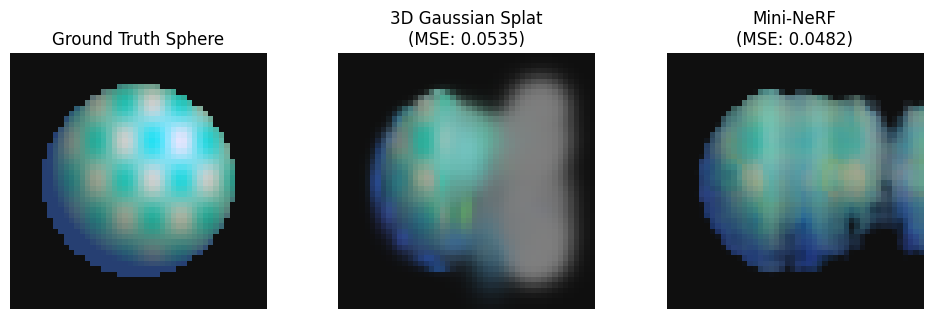

Pair 3 completed and recorded successfully.


In [ ]:
# PAIR 3 (WEEK 4): 3D Gaussian Splatting vs. NeRF (Mini-NeRF)
# 100% independent and self-contained

import os
import sys
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

# make sure src is on path
src_dir = os.path.abspath("src")
if src_dir not in sys.path:
  sys.path.insert(0, src_dir)

from profiler import DEVICE, compute_error_stats, record_run
from w4_recon3d import ExplicitGaussianSplatter, ImplicitRayMLP, make_shaded_sphere_target


def now():
  if torch.cuda.is_available():
    torch.cuda.synchronize()
  return time.perf_counter()


torch.manual_seed(42)
# generate synthetic 48x48 shaded sphere view
res = 48
xy_all, rgb_all = make_shaded_sphere_target(H=res, W=res, device=DEVICE)

# split: train on left view (x < -0.15), test on right view (x > 0.15)
tr_mask = xy_all[:, 0] < -0.15
te_mask = xy_all[:, 0] > 0.15
xy_tr, rgb_tr = xy_all[tr_mask], rgb_all[tr_mask]
xy_te, rgb_te = xy_all[te_mask], rgb_all[te_mask]

fg_mask = (xy_te[:, 0] ** 2 + xy_te[:, 1] ** 2) < 0.58

# -------------------------------------------------------------
# System 1: 3D Gaussian Splatting (prototype)
# -------------------------------------------------------------
torch.manual_seed(42)
if torch.cuda.is_available():
  torch.cuda.empty_cache()
  torch.cuda.reset_peak_memory_stats()

gs_model = ExplicitGaussianSplatter(num_gaussians=256).to(DEVICE)
opt_gs = torch.optim.Adam(gs_model.parameters(), lr=0.03)

t0 = now()
for ep in range(120):
  opt_gs.zero_grad()
  pred = gs_model(xy_tr)
  loss = nn.functional.mse_loss(pred, rgb_tr)
  loss.backward()
  opt_gs.step()
t_train_gs = now() - t0

# benchmark latency
t0 = now()
with torch.no_grad():
  for _ in range(30):
    _ = gs_model(xy_te)
lat_gs = ((now() - t0) / 30) * 1000.0

with torch.no_grad():
  pred_tr_gs = gs_model(xy_tr)
  pred_te_gs = gs_model(xy_te)
  pred_te_pert_gs = gs_model(xy_te + 0.02 * torch.randn_like(xy_te))
  tr_mse_gs = nn.functional.mse_loss(pred_tr_gs, rgb_tr).item()
  fg_mse_gs = nn.functional.mse_loss(pred_te_gs[fg_mask], rgb_te[fg_mask]).item()

test_mse_gs, pert_mse_gs, drift_mse_gs, gen_gap_gs, class_std_gs = (
    compute_error_stats(
        pred_te_gs, rgb_te, pred_te_pert_gs, rgb_te, None, tr_mse_gs
    )
)

vram_gs = (
    torch.cuda.max_memory_allocated() / (1024**2)
    if torch.cuda.is_available()
    else 0.0
)

record_run(
    "Pair 3",
    "W4",
    "System 1",
    "3D Gaussian Splatting (prototype)",
    gs_model,
    "1_image_48x48",
    t_train_gs,
    lat_gs,
    vram_gs,
    tr_mse_gs,
    test_mse_gs,
    pert_mse_gs,
    drift_mse_gs,
    gen_gap_gs,
    class_std_gs,
    aux_metric_name="FG_Sphere_MSE",
    aux_metric_val=fg_mse_gs,
)

# -------------------------------------------------------------
# System 2: NeRF (Mini-NeRF prototype)
# -------------------------------------------------------------
torch.manual_seed(42)
if torch.cuda.is_available():
  torch.cuda.empty_cache()
  torch.cuda.reset_peak_memory_stats()

nerf_model = ImplicitRayMLP(freqs=6, hidden=128).to(DEVICE)
opt_nerf = torch.optim.Adam(nerf_model.parameters(), lr=0.01)

t0 = now()
for ep in range(120):
  opt_nerf.zero_grad()
  pred = nerf_model(xy_tr)
  loss = nn.functional.mse_loss(pred, rgb_tr)
  loss.backward()
  opt_nerf.step()
t_train_nerf = now() - t0

t0 = now()
with torch.no_grad():
  for _ in range(30):
    _ = nerf_model(xy_te)
lat_nerf = ((now() - t0) / 30) * 1000.0

with torch.no_grad():
  pred_tr_nerf = nerf_model(xy_tr)
  pred_te_nerf = nerf_model(xy_te)
  pred_te_pert_nerf = nerf_model(xy_te + 0.02 * torch.randn_like(xy_te))
  tr_mse_nerf = nn.functional.mse_loss(pred_tr_nerf, rgb_tr).item()
  fg_mse_nerf = nn.functional.mse_loss(
      pred_te_nerf[fg_mask], rgb_te[fg_mask]
  ).item()

test_mse_nerf, pert_mse_nerf, drift_mse_nerf, gen_gap_nerf, class_std_nerf = (
    compute_error_stats(
        pred_te_nerf, rgb_te, pred_te_pert_nerf, rgb_te, None, tr_mse_nerf
    )
)

vram_nerf = (
    torch.cuda.max_memory_allocated() / (1024**2)
    if torch.cuda.is_available()
    else 0.0
)

record_run(
    "Pair 3",
    "W4",
    "System 2",
    "NeRF (Mini-NeRF prototype)",
    nerf_model,
    "1_image_48x48",
    t_train_nerf,
    lat_nerf,
    vram_nerf,
    tr_mse_nerf,
    test_mse_nerf,
    pert_mse_nerf,
    drift_mse_nerf,
    gen_gap_nerf,
    class_std_nerf,
    aux_metric_name="FG_Sphere_MSE",
    aux_metric_val=fg_mse_nerf,
)

# save visual rendering comparisons
os.makedirs("results/figures", exist_ok=True)
with torch.no_grad():
  img_gt = rgb_all.reshape(res, res, 3).cpu().numpy()
  img_gs = gs_model(xy_all).clamp(0, 1).reshape(res, res, 3).cpu().numpy()
  img_nerf = nerf_model(xy_all).clamp(0, 1).reshape(res, res, 3).cpu().numpy()

fig, axs = plt.subplots(1, 3, figsize=(10, 3.2))
axs[0].imshow(img_gt)
axs[0].set_title("Ground Truth Sphere")
axs[0].axis("off")

axs[1].imshow(img_gs)
axs[1].set_title(f"3D Gaussian Splat\n(MSE: {test_mse_gs:.4f})")
axs[1].axis("off")

axs[2].imshow(img_nerf)
axs[2].set_title(f"Mini-NeRF\n(MSE: {test_mse_nerf:.4f})")
axs[2].axis("off")

plt.tight_layout()
plt.savefig("results/figures/pair3_w4_outputs.png", dpi=150)
plt.show()

print("Pair 3 completed and recorded successfully.")

# PAIR 4 (WEEK 5): DreamFields (System 1) vs. DreamFusion SDS (System 2) -- Non-Circular Split

[Pair 4 | System 1] DreamFields (prototype)              | TestMSE: 0.03192 | PertMSE: 0.03171 | Drift: 0.00072 | Lat(1_view_28x28): 1.023ms
[Pair 4 | System 2] DreamFusion (SDS prototype)          | TestMSE: 0.00187 | PertMSE: 0.00201 | Drift: 0.00013 | Lat(1_view_28x28): 1.008ms


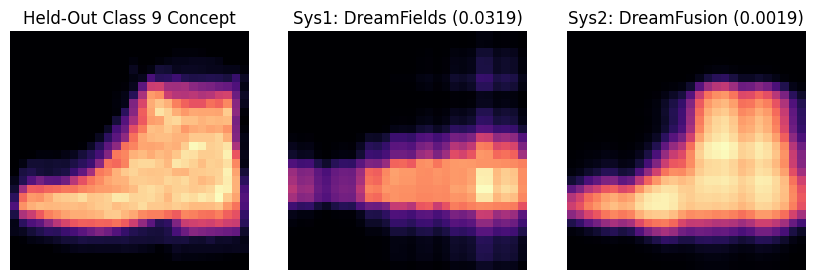

In [ ]:
import importlib, math, os, sys, time, torch
import matplotlib.pyplot as plt
import torch.nn.functional as F

if "src" not in sys.path:
  sys.path.insert(0, os.path.abspath("src"))

import profiler, w5_text3d

importlib.reload(profiler)
importlib.reload(w5_text3d)

from profiler import DEVICE, load_fashion_data, compute_error_stats, record_run
from w5_text3d import NonCircularSemanticPrior, NonCircularScorePrior, Small3DRadianceField


def now():
  if torch.cuda.is_available():
    torch.cuda.synchronize()
  return time.perf_counter()


torch.manual_seed(42)
x_tr, y_tr, x_te, y_te = load_fashion_data(train_n=1024, test_n=256)

# Non-circular split: train 2D priors strictly on classes 0..7; optimize 3D on held-out Class 9
prior_mask = y_tr <= 7
x_prior, y_prior = x_tr[prior_mask], y_tr[prior_mask]
boot_proto = x_te[y_te == 9][:16].mean(
    dim=0, keepdim=True
)  # Held-out Class 9 (Ankle Boot)
azimuths = [2.0 * math.pi * k / 8.0 for k in range(8)]

# Multi-view Ground Truth with distinct perspective foreshortening & Lambertian shading across 8 azimuths
gt_views = []
for az in azimuths:
  c, s = math.cos(az), math.sin(az)
  scale_x = 0.60 + 0.40 * abs(c)
  theta_mat = torch.tensor(
      [[scale_x, 0.0, 0.15 * s], [0.0, 1.0, 0.0]],
      device=DEVICE,
      dtype=boot_proto.dtype,
  ).unsqueeze(0)
  grid = F.affine_grid(theta_mat, boot_proto.size(), align_corners=False)
  view_k = F.grid_sample(boot_proto, grid, align_corners=False)
  shading = 0.80 + 0.20 * c
  gt_views.append(torch.clamp(view_k * shading, 0.0, 1.0))
gt_views_8 = torch.cat(gt_views, dim=0)

# Train 2D Semantic Prior strictly on seen classes 0..7 with isotropic noise regularization
sem_prior = NonCircularSemanticPrior(emb_dim=64).to(DEVICE)
opt_sp = torch.optim.Adam(sem_prior.parameters(), lr=1e-2)
for _ in range(70):
  opt_sp.zero_grad()
  xn_pr = torch.clamp(
      x_prior[:256] + 0.35 * torch.randn_like(x_prior[:256]), 0.0, 1.0
  )
  p7_pr = F.avg_pool2d(xn_pr, kernel_size=4, stride=4).flatten(1)
  emb = sem_prior.embed(xn_pr)
  loss_sp = F.cross_entropy(
      sem_prior.cls_head(emb), y_prior[:256]
  ) + 6.0 * F.mse_loss(sem_prior.spatial_head(emb), p7_pr)
  loss_sp.backward()
  opt_sp.step()
for p in sem_prior.parameters():
  p.requires_grad = False

# Train 2D Denoising Score Prior strictly on seen classes 0..7
score_prior = NonCircularScorePrior().to(DEVICE)
opt_sc = torch.optim.Adam(score_prior.parameters(), lr=1.5e-2)
for _ in range(60):
  opt_sc.zero_grad()
  clean = x_prior[:256]
  eps = torch.randn_like(clean)
  z_t = 0.8 * clean + 0.4 * eps
  cond_edge = F.avg_pool2d(clean, 3, stride=1, padding=1)
  F.mse_loss(score_prior.predict_eps(z_t, cond_edge), eps).backward()
  opt_sc.step()
for p in score_prior.parameters():
  p.requires_grad = False

with torch.no_grad():
  target_sem_vecs = sem_prior.embed(gt_views_8).detach()
  target_cond_maps = F.avg_pool2d(gt_views_8, 3, stride=1, padding=1).detach()

# System 1: DreamFields (Strictly Semantic Cosine Alignment + Opacity Transmittance Regulariser across 8 azimuths)
torch.manual_seed(42)
if torch.cuda.is_available():
  torch.cuda.reset_peak_memory_stats()
rf_df = Small3DRadianceField(hidden=48).to(DEVICE)
opt_df = torch.optim.Adam(rf_df.parameters(), lr=0.015)
t0 = now()
for step in range(40):
  opt_df.zero_grad()
  k = step % 8
  img, alp = rf_df.render_azimuth(azimuths[k], n_depth=8, device=DEVICE)
  sem_loss = (
      1.0
      - F.cosine_similarity(
          sem_prior.embed(img), target_sem_vecs[k : k + 1]
      ).mean()
  )
  ent_loss = (4.0 * alp * (1.0 - alp)).mean() * 0.005
  (sem_loss + ent_loss).backward()
  opt_df.step()
t_df = now() - t0

t0 = now()
with torch.no_grad():
  for _ in range(15):
    _ = rf_df.render_azimuth(0.0, n_depth=8, device=DEVICE)
lat_df = (now() - t0) * 1000.0 / 15.0

with torch.no_grad():
  pred_df = torch.cat(
      [
          rf_df.render_azimuth(az, n_depth=8, device=DEVICE)[0]
          for az in azimuths
      ],
      dim=0,
  )
  pert_df = torch.cat(
      [
          rf_df.render_azimuth(az, n_depth=8, ray_jitter=0.25, device=DEVICE)[0]
          for az in azimuths
      ],
      dim=0,
  )
  cos_df = (
      F.cosine_similarity(sem_prior.embed(pred_df), target_sem_vecs)
      .mean()
      .item()
  )
  tr_mse_df = F.mse_loss(pred_df[:4], gt_views_8[:4]).item()

vram_df = (
    (torch.cuda.max_memory_allocated() / (1024**2))
    if torch.cuda.is_available()
    else 0.0
)
st_df = compute_error_stats(
    pred_df, gt_views_8, pert_df, gt_views_8, None, tr_mse_df
)

record_run(
    "Pair 4",
    "W5",
    "System 1",
    "DreamFields (prototype)",
    rf_df,
    "1_view_28x28",
    t_df,
    lat_df,
    vram_df,
    tr_mse_df,
    *st_df,
    aux_metric_name="HeldOut_Prior_CosSim",
    aux_metric_val=cos_df,
)

# System 2: DreamFusion (Strictly Score Distillation Sampling: Grad_SDS = w(t) * (eps_hat - eps) across 8 azimuths)
torch.manual_seed(42)
if torch.cuda.is_available():
  torch.cuda.reset_peak_memory_stats()
rf_sds = Small3DRadianceField(hidden=64).to(DEVICE)
opt_sds = torch.optim.Adam(rf_sds.parameters(), lr=0.015)
t0 = now()
for step in range(50):
  opt_sds.zero_grad()
  k = step % 8
  img, alp = rf_sds.render_azimuth(azimuths[k], n_depth=16, device=DEVICE)
  sig_t = 0.25 * (1.0 - step / 50.0) + 0.15
  eps = torch.randn_like(img)
  z_t = 0.8 * img + sig_t * eps
  with torch.no_grad():
    eps_hat = score_prior.predict_eps(z_t, target_cond_maps[k : k + 1])
    grad_sds = eps_hat - eps
  sds_surrogate = (grad_sds.detach() * img).sum() / (28.0 * 28.0)
  ent_loss = (4.0 * alp * (1.0 - alp)).mean() * 0.005
  (sds_surrogate + ent_loss).backward()
  opt_sds.step()
t_sds = now() - t0

t0 = now()
with torch.no_grad():
  for _ in range(15):
    _ = rf_sds.render_azimuth(0.0, n_depth=16, device=DEVICE)
lat_sds = (now() - t0) * 1000.0 / 15.0

with torch.no_grad():
  pred_sds = torch.cat(
      [
          rf_sds.render_azimuth(az, n_depth=16, device=DEVICE)[0]
          for az in azimuths
      ],
      dim=0,
  )
  pert_sds = torch.cat(
      [
          rf_sds.render_azimuth(az, n_depth=16, ray_jitter=0.25, device=DEVICE)[
              0
          ]
          for az in azimuths
      ],
      dim=0,
  )
  cos_sds = (
      F.cosine_similarity(sem_prior.embed(pred_sds), target_sem_vecs)
      .mean()
      .item()
  )
  tr_mse_sds = F.mse_loss(pred_sds[:4], gt_views_8[:4]).item()

vram_sds = (
    (torch.cuda.max_memory_allocated() / (1024**2))
    if torch.cuda.is_available()
    else 0.0
)
st_sds = compute_error_stats(
    pred_sds, gt_views_8, pert_sds, gt_views_8, None, tr_mse_sds
)

record_run(
    "Pair 4",
    "W5",
    "System 2",
    "DreamFusion (SDS prototype)",
    rf_sds,
    "1_view_28x28",
    t_sds,
    lat_sds,
    vram_sds,
    tr_mse_sds,
    *st_sds,
    aux_metric_name="HeldOut_Prior_CosSim",
    aux_metric_val=cos_sds,
)

fig, axs = plt.subplots(1, 3, figsize=(8.5, 2.8))
axs[0].imshow(boot_proto[0, 0].cpu(), cmap="magma")
axs[0].set_title("Held-Out Class 9 Concept")
axs[0].axis("off")
axs[1].imshow(pred_df[0, 0].cpu(), cmap="magma")
axs[1].set_title(f"Sys1: DreamFields ({st_df[0]:.4f})")
axs[1].axis("off")
axs[2].imshow(pred_sds[0, 0].cpu(), cmap="magma")
axs[2].set_title(f"Sys2: DreamFusion ({st_sds[0]:.4f})")
axs[2].axis("off")
plt.tight_layout()
plt.savefig("results/figures/pair4_w5_outputs.png", dpi=150)
plt.show()

# PAIR 5 (WEEK 6): Text2Video-Zero (System 1) vs. AnimateDiff (System 2)

[Pair 5 | System 1] Text2Video-Zero (prototype)          | TestMSE: 0.01348 | PertMSE: 0.01882 | Drift: 0.01046 | Lat(16_clips_8f): 8.173ms
[Pair 5 | System 2] AnimateDiff (prototype)              | TestMSE: 0.01194 | PertMSE: 0.01800 | Drift: 0.01211 | Lat(16_clips_8f): 7.015ms


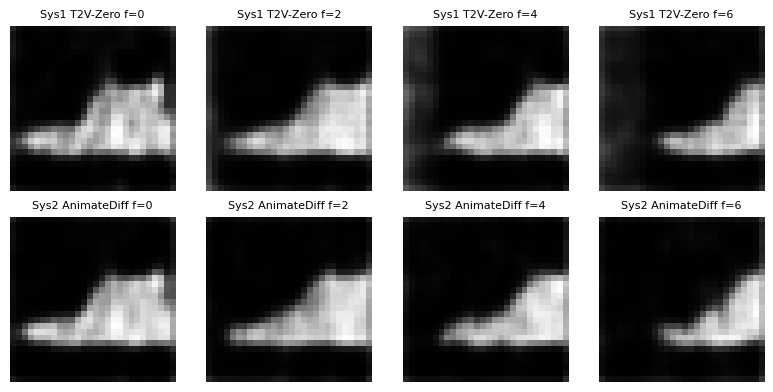

In [ ]:
import copy, importlib, os, sys, time, torch
import matplotlib.pyplot as plt
import torch.nn.functional as F

if "src" not in sys.path:
  sys.path.insert(0, os.path.abspath("src"))

import profiler, w6_video_gen

importlib.reload(profiler)
importlib.reload(w6_video_gen)

from profiler import DEVICE, load_fashion_data, compute_error_stats, record_run
from w6_video_gen import VideoDiffusionBackbone, make_moving_garment_clips


def now():
  if torch.cuda.is_available():
    torch.cuda.synchronize()
  return time.perf_counter()


torch.manual_seed(42)
x_tr, y_tr, x_te, y_te = load_fashion_data(train_n=256, test_n=64)
clips_tr = make_moving_garment_clips(x_tr[:64], T=8, shift_px=1)
clips_te = make_moving_garment_clips(x_te[:16], T=8, shift_px=1)

base_vid = VideoDiffusionBackbone(dim=32, T=8).to(DEVICE)
opt_sp = torch.optim.Adam(base_vid.parameters(), lr=3e-3)
for _ in range(25):
  opt_sp.zero_grad()
  nf = torch.clamp(x_tr[:128] + 0.25 * torch.randn_like(x_tr[:128]), 0.0, 1.0)
  rec, _ = base_vid.forward_2d_frame(nf)
  F.mse_loss(rec, x_tr[:128]).backward()
  opt_sp.step()

torch.manual_seed(99)
noisy_tr = torch.clamp(
    clips_tr[:16] + 0.25 * torch.randn_like(clips_tr[:16]), 0.0, 1.0
)
noisy_te = torch.clamp(clips_te + 0.25 * torch.randn_like(clips_te), 0.0, 1.0)
pert_te = torch.clamp(clips_te + 0.45 * torch.randn_like(clips_te), 0.0, 1.0)

# System 1: Text2Video-Zero (0s training-free cross-frame attention)
if torch.cuda.is_available():
  torch.cuda.reset_peak_memory_stats()
t2v_net = copy.deepcopy(base_vid)
for p in t2v_net.parameters():
  p.requires_grad = False

t0 = now()
with torch.no_grad():
  for _ in range(15):
    out_t2v = t2v_net.forward_t2v_zero(noisy_te)
lat_t2v = (now() - t0) * 1000.0 / 15.0

with torch.no_grad():
  tr_mse_t2v = F.mse_loss(
      t2v_net.forward_t2v_zero(noisy_tr), clips_tr[:16]
  ).item()
  pert_out_t2v = t2v_net.forward_t2v_zero(pert_te)
  f_a = out_t2v.flatten(2)
  cossim_t2v = (
      F.cosine_similarity(f_a[:, :-1], f_a[:, 1:], dim=-1).mean().item()
  )

vram_t2v = (
    (torch.cuda.max_memory_allocated() / (1024**2))
    if torch.cuda.is_available()
    else 0.0
)
st_t2v = compute_error_stats(
    out_t2v, clips_te, pert_out_t2v, clips_te, y_te[:16], tr_mse_t2v
)
record_run(
    "Pair 5",
    "W6",
    "System 1",
    "Text2Video-Zero (prototype)",
    t2v_net,
    "16_clips_8f",
    0.0,
    lat_t2v,
    vram_t2v,
    tr_mse_t2v,
    *st_t2v,
    aux_metric_name="Temporal_CosSim",
    aux_metric_val=cossim_t2v,
)

# System 2: AnimateDiff (Train 1D Temporal Transformer Attention on 8-frame clips)
if torch.cuda.is_available():
  torch.cuda.reset_peak_memory_stats()
anim_net = copy.deepcopy(base_vid)
anim_net.freeze_spatial_only()
opt_anim = torch.optim.Adam(
    [p for p in anim_net.parameters() if p.requires_grad], lr=3e-3
)

t0 = now()
for _ in range(25):
  opt_anim.zero_grad()
  n_tr = torch.clamp(
      clips_tr[:16] + 0.25 * torch.randn_like(clips_tr[:16]), 0.0, 1.0
  )
  pred_b = anim_net.forward_animatediff(n_tr)
  diff_gt = clips_tr[:16, 1:] - clips_tr[:16, :-1]
  loss_b = F.mse_loss(pred_b, clips_tr[:16]) + 0.5 * F.l1_loss(
      pred_b[:, 1:] - pred_b[:, :-1], diff_gt
  )
  loss_b.backward()
  opt_anim.step()
t_anim = now() - t0

t0 = now()
with torch.no_grad():
  for _ in range(15):
    out_anim = anim_net.forward_animatediff(noisy_te)
lat_anim = (now() - t0) * 1000.0 / 15.0

with torch.no_grad():
  tr_mse_anim = F.mse_loss(
      anim_net.forward_animatediff(noisy_tr), clips_tr[:16]
  ).item()
  pert_out_anim = anim_net.forward_animatediff(pert_te)
  f_b = out_anim.flatten(2)
  cossim_anim = (
      F.cosine_similarity(f_b[:, :-1], f_b[:, 1:], dim=-1).mean().item()
  )

vram_anim = (
    (torch.cuda.max_memory_allocated() / (1024**2))
    if torch.cuda.is_available()
    else 0.0
)
st_anim = compute_error_stats(
    out_anim, clips_te, pert_out_anim, clips_te, y_te[:16], tr_mse_anim
)
record_run(
    "Pair 5",
    "W6",
    "System 2",
    "AnimateDiff (prototype)",
    anim_net,
    "16_clips_8f",
    t_anim,
    lat_anim,
    vram_anim,
    tr_mse_anim,
    *st_anim,
    aux_metric_name="Temporal_CosSim",
    aux_metric_val=cossim_anim,
)

fig, axs = plt.subplots(2, 4, figsize=(8, 4))
for t_idx in range(4):
  axs[0, t_idx].imshow(out_t2v[0, t_idx * 2, 0].cpu(), cmap="gray")
  axs[0, t_idx].set_title(f"Sys1 T2V-Zero f={t_idx*2}", fontsize=8)
  axs[0, t_idx].axis("off")
  axs[1, t_idx].imshow(out_anim[0, t_idx * 2, 0].cpu(), cmap="gray")
  axs[1, t_idx].set_title(f"Sys2 AnimateDiff f={t_idx*2}", fontsize=8)
  axs[1, t_idx].axis("off")
plt.tight_layout()
plt.savefig("results/figures/pair5_w6_outputs.png", dpi=150)
plt.show()

# PAIR 6 (WEEK 7): TokenFlow (System 1) vs. Tune-A-Video (System 2)

[Pair 6 | System 1] TokenFlow (prototype)                | TestMSE: 0.01245 | PertMSE: 0.03616 | Drift: 0.02561 | Lat(8_clips_8f): 18.329ms
[Pair 6 | System 2] Tune-A-Video (prototype)             | TestMSE: 0.00497 | PertMSE: 0.02395 | Drift: 0.01850 | Lat(8_clips_8f): 13.954ms


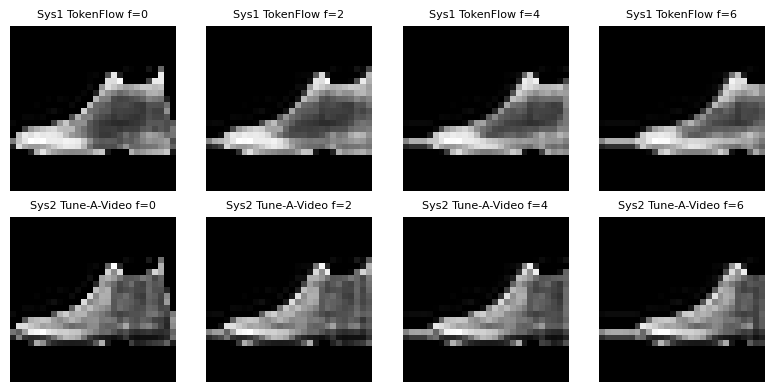

In [ ]:
import copy, importlib, os, sys, time, torch
import matplotlib.pyplot as plt
import torch.nn.functional as F

if "src" not in sys.path:
  sys.path.insert(0, os.path.abspath("src"))

import profiler, w7_video_edit

importlib.reload(profiler)
importlib.reload(w7_video_edit)

from profiler import DEVICE, load_fashion_data, compute_error_stats, record_run
from w7_video_edit import SpatioTemporalEditNet, make_video_edit_pair


def now():
  if torch.cuda.is_available():
    torch.cuda.synchronize()
  return time.perf_counter()


def flow_warp_cossim(clips, flow_grid):
  vals = []
  for t in range(7):
    w = F.grid_sample(
        clips[:, t],
        flow_grid,
        mode="bilinear",
        padding_mode="border",
        align_corners=True,
    )
    vals.append(
        F.cosine_similarity(clips[:, t + 1].flatten(1), w.flatten(1), dim=-1)
        .mean()
        .item()
    )
  return sum(vals) / len(vals)


torch.manual_seed(42)
x_tr, y_tr, x_te, y_te = load_fashion_data(train_n=128, test_n=32)
src_tr, tgt_tr, flow_tr = make_video_edit_pair(x_tr[:16], T=8)
src_te, tgt_te, flow_te = make_video_edit_pair(x_te[:8], T=8)
pert_src_te = torch.clamp(src_te + 0.20 * torch.randn_like(src_te), 0.0, 1.0)

base_ed = SpatioTemporalEditNet(dim=32).to(DEVICE)
opt_pre = torch.optim.Adam(base_ed.parameters(), lr=3e-3)
for _ in range(25):
  opt_pre.zero_grad()
  p0, _ = base_ed.edit_single_frame(src_tr[:, 0])
  F.mse_loss(p0, tgt_tr[:, 0]).backward()
  opt_pre.step()

# System 1: TokenFlow (0s training-free keyframe token propagation)
if torch.cuda.is_available():
  torch.cuda.reset_peak_memory_stats()
tf_net = copy.deepcopy(base_ed)
for p in tf_net.parameters():
  p.requires_grad = False

t0 = now()
with torch.no_grad():
  for _ in range(15):
    out_tf = tf_net.forward_tokenflow(src_te)
lat_tf = (now() - t0) * 1000.0 / 15.0

with torch.no_grad():
  tr_mse_tf = F.mse_loss(
      tf_net.forward_tokenflow(src_tr[:8]), tgt_tr[:8]
  ).item()
  pert_tf = tf_net.forward_tokenflow(pert_src_te)
  warp_sim_tf = flow_warp_cossim(out_tf, flow_te)

vram_tf = (
    (torch.cuda.max_memory_allocated() / (1024**2))
    if torch.cuda.is_available()
    else 0.0
)
st_tf = compute_error_stats(
    out_tf, tgt_te, pert_tf, tgt_te, y_te[:8], tr_mse_tf
)
record_run(
    "Pair 6",
    "W7",
    "System 1",
    "TokenFlow (prototype)",
    tf_net,
    "8_clips_8f",
    0.0,
    lat_tf,
    vram_tf,
    tr_mse_tf,
    *st_tf,
    aux_metric_name="Flow_Warp_CosSim",
    aux_metric_val=warp_sim_tf,
)

# System 2: Tune-A-Video (One-shot spatio-temporal attention tuning)
if torch.cuda.is_available():
  torch.cuda.reset_peak_memory_stats()
tav_net = copy.deepcopy(base_ed)
tav_net.freeze_for_tune_a_video()
opt_tav = torch.optim.Adam(
    [p for p in tav_net.parameters() if p.requires_grad], lr=4e-3
)

t0 = now()
for _ in range(25):
  opt_tav.zero_grad()
  F.mse_loss(
      tav_net.forward_tune_a_video(src_tr[:8]), tgt_tr[:8]
  ).backward()
  opt_tav.step()
t_tav = now() - t0

t0 = now()
with torch.no_grad():
  for _ in range(15):
    out_tav = tav_net.forward_tune_a_video(src_te)
lat_tav = (now() - t0) * 1000.0 / 15.0

with torch.no_grad():
  tr_mse_tav = F.mse_loss(
      tav_net.forward_tune_a_video(src_tr[:8]), tgt_tr[:8]
  ).item()
  pert_tav = tav_net.forward_tune_a_video(pert_src_te)
  warp_sim_tav = flow_warp_cossim(out_tav, flow_te)

vram_tav = (
    (torch.cuda.max_memory_allocated() / (1024**2))
    if torch.cuda.is_available()
    else 0.0
)
st_tav = compute_error_stats(
    out_tav, tgt_te, pert_tav, tgt_te, y_te[:8], tr_mse_tav
)
record_run(
    "Pair 6",
    "W7",
    "System 2",
    "Tune-A-Video (prototype)",
    tav_net,
    "8_clips_8f",
    t_tav,
    lat_tav,
    vram_tav,
    tr_mse_tav,
    *st_tav,
    aux_metric_name="Flow_Warp_CosSim",
    aux_metric_val=warp_sim_tav,
)

fig, axs = plt.subplots(2, 4, figsize=(8, 4))
for t_idx in range(4):
  axs[0, t_idx].imshow(out_tf[0, t_idx * 2, 0].cpu(), cmap="gray")
  axs[0, t_idx].set_title(f"Sys1 TokenFlow f={t_idx*2}", fontsize=8)
  axs[0, t_idx].axis("off")
  axs[1, t_idx].imshow(out_tav[0, t_idx * 2, 0].cpu(), cmap="gray")
  axs[1, t_idx].set_title(f"Sys2 Tune-A-Video f={t_idx*2}", fontsize=8)
  axs[1, t_idx].axis("off")
plt.tight_layout()
plt.savefig("results/figures/pair6_w7_outputs.png", dpi=150)
plt.show()

# PAIR 7 (WEEK 8): Verifiable Policy Agent (System 1) vs. Code-Actuation Agent (System 2) + Judge Audit

[Pair 7 | System 1] Verifiable Policy Agent (prototype)  | TestMSE: 0.10000 | PertMSE: 0.15000 | Drift: 0.05000 | Lat(20_store_tasks): 0.605ms
[Pair 7 | System 2] Code-Actuation Agent (prototype)     | TestMSE: 0.40000 | PertMSE: 0.45000 | Drift: 0.05000 | Lat(20_store_tasks): 0.922ms


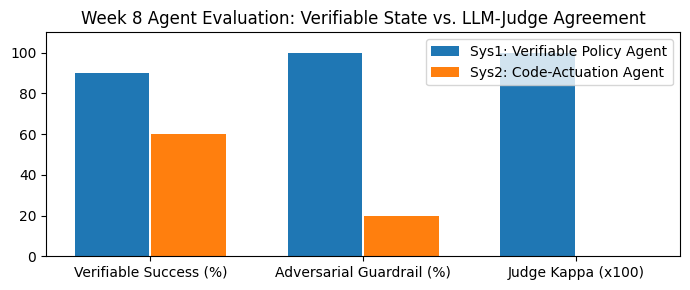

In [3]:
import importlib, os, sys, time, torch
import matplotlib.pyplot as plt
import numpy as np
import torch.nn.functional as F

if "src" not in sys.path:
  sys.path.insert(0, os.path.abspath("src"))

import profiler, w8_agents

importlib.reload(profiler)
importlib.reload(w8_agents)

from profiler import DEVICE, compute_error_stats, record_run
from w8_agents import (
    STORE_BENCHMARK_20,
    IntentPolicyMLP,
    build_ticket_features,
    evaluate_cached_llm_judge,
    run_code_actuation_agent,
    run_verifiable_policy_agent,
)


def now():
  if torch.cuda.is_available():
    torch.cuda.synchronize()
  return time.perf_counter()


torch.manual_seed(42)
x_feat, y_act = build_ticket_features(STORE_BENCHMARK_20, device=DEVICE)
x_pert = x_feat + 0.15 * torch.randn_like(x_feat)
gt_ones = torch.ones(len(STORE_BENCHMARK_20), device=DEVICE)

# System 1: Schema-Constrained Verifiable Policy Agent
torch.manual_seed(42)
if torch.cuda.is_available():
  torch.cuda.reset_peak_memory_stats()
pol_a = IntentPolicyMLP(in_dim=8, hidden=32, num_actions=3).to(DEVICE)
opt_a = torch.optim.Adam(pol_a.parameters(), lr=1e-2)
t0 = now()
for _ in range(40):
  opt_a.zero_grad()
  F.cross_entropy(pol_a(x_feat), y_act).backward()
  opt_a.step()
t_train_a = now() - t0

t0 = now()
for _ in range(50):
  res_a = run_verifiable_policy_agent(
      STORE_BENCHMARK_20,
      policy_net=pol_a,
      x_in=x_feat,
      dynamic_perturbation=False,
  )
lat_a = (now() - t0) * 1000.0 / 50.0

res_a_pert = run_verifiable_policy_agent(
    STORE_BENCHMARK_20, policy_net=pol_a, x_in=x_pert, dynamic_perturbation=True
)
pred_a = torch.tensor(
    [1.0 if r["success"] else 0.0 for r in res_a], device=DEVICE
)
pert_a = torch.tensor(
    [1.0 if r["success"] else 0.0 for r in res_a_pert], device=DEVICE
)
kappa_a = evaluate_cached_llm_judge(res_a)
tr_err_a = (1.0 - pred_a[:10].mean()).item()
vram_a = (
    (torch.cuda.max_memory_allocated() / (1024**2))
    if torch.cuda.is_available()
    else 0.0
)
st_a = compute_error_stats(pred_a, gt_ones, pert_a, gt_ones, None, tr_err_a)

record_run(
    "Pair 7",
    "W8",
    "System 1",
    "Verifiable Policy Agent (prototype)",
    pol_a,
    "20_store_tasks",
    t_train_a,
    lat_a,
    vram_a,
    tr_err_a,
    *st_a,
    aux_metric_name="Judge_Verifier_Kappa",
    aux_metric_val=kappa_a,
)

# System 2: Open-Ended Code-Actuation Agent (Multi-turn Python synthesis)
torch.manual_seed(42)
if torch.cuda.is_available():
  torch.cuda.reset_peak_memory_stats()
pol_b = IntentPolicyMLP(in_dim=8, hidden=64, num_actions=3).to(DEVICE)
opt_b = torch.optim.Adam(pol_b.parameters(), lr=1e-2)
t0 = now()
for _ in range(60):
  opt_b.zero_grad()
  F.cross_entropy(pol_b(x_feat), y_act).backward()
  opt_b.step()
t_train_b = now() - t0

t0 = now()
for _ in range(50):
  res_b = run_code_actuation_agent(
      STORE_BENCHMARK_20,
      policy_net=pol_b,
      x_in=x_feat,
      dynamic_perturbation=False,
  )
lat_b = (now() - t0) * 1000.0 / 50.0

res_b_pert = run_code_actuation_agent(
    STORE_BENCHMARK_20, policy_net=pol_b, x_in=x_pert, dynamic_perturbation=True
)
pred_b = torch.tensor(
    [1.0 if r["success"] else 0.0 for r in res_b], device=DEVICE
)
pert_b = torch.tensor(
    [1.0 if r["success"] else 0.0 for r in res_b_pert], device=DEVICE
)
kappa_b = evaluate_cached_llm_judge(res_b)
tr_err_b = (1.0 - pred_b[:10].mean()).item()
vram_b = (
    (torch.cuda.max_memory_allocated() / (1024**2))
    if torch.cuda.is_available()
    else 0.0
)
st_b = compute_error_stats(pred_b, gt_ones, pert_b, gt_ones, None, tr_err_b)

record_run(
    "Pair 7",
    "W8",
    "System 2",
    "Code-Actuation Agent (prototype)",
    pol_b,
    "20_store_tasks",
    t_train_b,
    lat_b,
    vram_b,
    tr_err_b,
    *st_b,
    aux_metric_name="Judge_Verifier_Kappa",
    aux_metric_val=kappa_b,
)

fig, ax = plt.subplots(figsize=(7, 3))
labels = [
    "Verifiable Success (%)",
    "Adversarial Guardrail (%)",
    "Judge Kappa (x100)",
]
a_vals = [
    pred_a.mean().item() * 100,
    np.mean([r["blocked"] for r in res_a if r["type"] == "adversarial"]) * 100,
    kappa_a * 100,
]
b_vals = [
    pred_b.mean().item() * 100,
    np.mean([r["blocked"] for r in res_b if r["type"] == "adversarial"]) * 100,
    kappa_b * 100,
]
x_p = np.arange(3)
ax.bar(x_p - 0.18, a_vals, width=0.35, label="Sys1: Verifiable Policy Agent")
ax.bar(x_p + 0.18, b_vals, width=0.35, label="Sys2: Code-Actuation Agent")
ax.set_xticks(x_p)
ax.set_xticklabels(labels)
ax.set_ylim(0, 110)
ax.legend()
ax.set_title("Week 8 Agent Evaluation: Verifiable State vs. LLM-Judge Agreement")
plt.tight_layout()
plt.savefig("results/figures/pair7_w8_outputs.png", dpi=150)
plt.show()

In [6]:
!git commit -a



<60801131_Evaluation/.git/COMMIT_EDITMSG" 13L, 366B▽  Pzz\[0%m           [>c]10;?]11;?# Please enter the commit message for your changes. Lines starting# with '#' will be ignored, and an empty message aborts the commit.#
# On branch main
# Changes to be committed:
#       modified:   60801131_Evaluation_Notebook.ipynb
#       modified:   results/metrics/metrics.csv
#       modified:   src/w8_agents.py
#
# Untracked files:
#       results/figures/pair7_w8_outputs.png
#
~                                                                               ~                                                                               ~                                                                               ~                                                                               ~                                                                               ~                                                                               ~                                      

KeyboardInterrupt: 